<a href="https://colab.research.google.com/github/deboraachriss/Face-Emotion-Predictions/blob/main/Face%20Emotion%20Predictions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install deepface
!pip install retina-face


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.1/133.1 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.0/85.0 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.4/59.4 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 50.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 82.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.6/44.6 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 297.0/297.0 kB 30.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.7/98.7 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.1/250.1 kB 24.6 MB/s eta 0:00:00
  Attempting uninstall: pytest
    Found existing installation: pytest 8.4.2
    Uninstalling pytest-8.4.2:
      Successfully uninstalled pytest-8.4.2


In [ ]:
from deepface import DeepFace
import cv2
import matplotlib.pyplot as plt
from google.colab import files
import numpy as np


25-12-09 02:57:17 - Directory /root/.deepface has been created
25-12-09 02:57:17 - Directory /root/.deepface/weights has been created


In [ ]:
uploaded = files.upload()
img_path = list(uploaded.keys())[0]
print("Uploaded image:", img_path)


Saving Screenshot 2025-12-08 210052.png to Screenshot 2025-12-08 210052.png
Uploaded image: Screenshot 2025-12-08 210052.png


In [ ]:
import numpy as np
np.float = float
np.float32 = float

from deepface import DeepFace
import cv2
import matplotlib.pyplot as plt

def predict_emotion_deepface(image_path):

    result = DeepFace.analyze(
        img_path=image_path,
        actions=['emotion'],
        enforce_detection=False
    )

    emotion = result[0]['dominant_emotion']
    scores = result[0]['emotion']

    scores = {k: float(v) for k, v in scores.items()}

    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.title(f"Predicted Emotion: {emotion}")
    plt.axis("off")
    plt.show()

    print("Emotion Scores:")
    print("{")
    for k, v in scores.items():
        if k == emotion:
            print(f"  \033[1m'{k}': {v},\033[0m")
        else:
            print(f"  '{k}': {v},")
    print("}")
    print(f"\nDominant Emotion: \033[1m{emotion}\033[0m")


25-12-09 02:58:07 - 🔗 facial_expression_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5 to /root/.deepface/weights/facial_expression_model_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5
To: /root/.deepface/weights/facial_expression_model_weights.h5
100%|██████████| 5.98M/5.98M [00:00<00:00, 88.0MB/s]


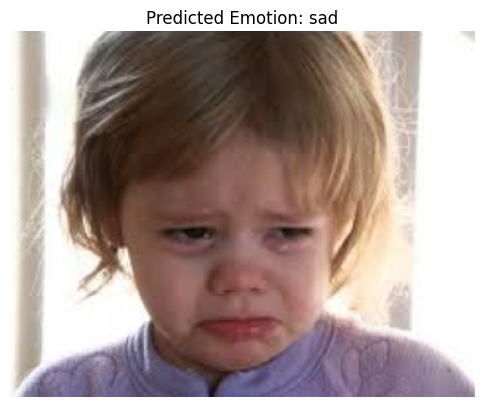

Emotion Scores:
{
  'angry': 4.022308349609375,
  'disgust': 0.13204853236675262,
  'fear': 25.29348373413086,
  'happy': 0.00010055398161057383,
  'sad': 68.61505126953125,
  'surprise': 7.160389941418543e-05,
  'neutral': 1.9369360208511353,
}

Dominant Emotion: sad


In [ ]:
predict_emotion_deepface(img_path)
